# Examen — Módulo 1: Preparación de datos
**Aprendizaje Supervisado · Evaluación de las sesiones 1–3** (EDA, preprocesamiento, ingeniería y selección de variables)

**Instrucciones**

- Trabajo **individual**. Duración sugerida: **120 minutos**. Material permitido: tus notas, la presentación y la documentación oficial de pandas, scikit-learn y matplotlib.
- Escribe tu nombre en la primera celda de código (`NOMBRE`).
- Sustituye cada `...` (marcado con ✏️) por tu código. En las preguntas con **“Respuesta:”**, escribe tu explicación en la celda de texto que sigue (editando la celda de Markdown).
- Antes de entregar, ejecuta **Kernel → Reiniciar y ejecutar todo**; el notebook debe correr de principio a fin sin errores.
- Los datos son simulados y se generan con semilla fija: tus resultados deben ser reproducibles.
- Se evalúa tanto el **código** como la **calidad de la justificación**. Las respuestas escritas deben ser breves y precisas.

| Parte | Tema | Puntos |
|---|---|---|
| I | Análisis exploratorio de datos | 30 |
| II | Preprocesamiento de datos | 35 |
| III | Ingeniería y selección de variables | 35 |
| | **Total** | **100** |


In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder,
                                   OrdinalEncoder, PolynomialFeatures)
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.feature_selection import (VarianceThreshold, SelectKBest, f_classif, mutual_info_classif,
                                       RFE, RFECV, SelectFromModel)
from sklearn.metrics import mean_squared_error

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})

NOMBRE =  "Alondra E. Matos Mendoza"


In [2]:
# ---------------------------------------------------------------------------------------------
# Generadores de datos (NO los modifiques; no necesitas leerlos para resolver el examen)
# ---------------------------------------------------------------------------------------------
def genera_viviendas(n=1200, seed=2026):
    """Viviendas en venta en una ciudad (datos simulados). Precio en miles de pesos."""
    r = np.random.default_rng(seed)
    zona = r.choice(["Norte", "Centro", "Poniente", "Oriente", "Sur", "Costa"], n, p=[.30, .15, .22, .14, .17, .02])
    acab = r.choice(["Básico", "Medio", "Alto", "Premium"], n, p=[.30, .40, .22, .08])
    sup = np.exp(r.normal(np.log(110), .38, n)).round(0)
    rec = np.clip(np.round(sup / 45 + r.normal(0, .6, n)), 1, 6).astype(int)
    ant = np.clip(r.gamma(1.6, 9, n), 0, 70).round(0)
    dist = np.round(r.gamma(2.2, 3.2, n), 1)
    zef = pd.Series(zona).map({"Norte": .25, "Centro": .05, "Poniente": .10, "Oriente": -.20, "Sur": -.30, "Costa": .55}).values
    aef = pd.Series(acab).map({"Básico": 0, "Medio": .18, "Alto": .40, "Premium": .75}).values
    lp = 1.2 + .85 * np.log(sup) + zef + aef - .008 * ant - .035 * dist + .04 * rec + r.normal(0, .17, n)
    precio = (np.exp(lp) * 25).round(0)
    idx = r.choice(n, 10, replace=False)
    precio[idx] *= r.uniform(3.5, 6, 10)
    df = pd.DataFrame(dict(zona=zona, acabados=acab, superficie_m2=sup, recamaras=rec,
                           antiguedad_anios=ant, dist_centro_km=dist, precio_miles=precio.round(0)))
    pm = np.where(np.isin(zona, ["Sur", "Oriente"]), .22, .04)
    df.loc[r.random(n) < pm, "antiguedad_anios"] = np.nan
    df.loc[r.random(n) < .04, "superficie_m2"] = np.nan
    return df


def genera_biomarcadores(n=400, seed=7):
    """400 pacientes, 26 mediciones de laboratorio y un diagnóstico y ∈ {0, 1} (datos simulados)."""
    r = np.random.default_rng(seed)
    y = r.integers(0, 2, n)
    s = 2 * y - 1
    a = r.normal(0.9 * s, 1.0)
    b = 100 + 15 * r.normal(0.6 * s, 1.0)
    c = 0.02 * r.normal(0.8 * s, 1.0)
    cuad = np.where(y == 1, r.choice([-1, 1], n) * r.normal(1.6, .35, n), r.normal(0, .45, n))
    a_copia = a + r.normal(0, .15, n)
    casi = 5 + 1e-3 * r.normal(0, 1, n)
    ruido = r.normal(0, 1, (n, 20)) * r.choice([1, 1, 1, 10, 50], 20)
    cols = {"lin_a": a, "lin_b": b, "lin_c": c, "cuad": cuad, "lin_a_copia": a_copia, "casi_const": casi}
    for i in range(20):
        cols[f"ruido_{i + 1:02d}"] = ruido[:, i]
    return pd.DataFrame(cols), pd.Series(y, name="y")


---
## Parte I — Análisis exploratorio de datos (30 puntos)

Trabajarás con `viv`: **1 200 viviendas en venta** de una ciudad (datos simulados).
Variables: `zona` y `acabados` (categóricas; `acabados` es ordinal: Básico < Medio < Alto < Premium), `superficie_m2`, `recamaras`,
`antiguedad_anios`, `dist_centro_km` y el objetivo `precio_miles` (miles de pesos). Hay valores faltantes.

In [3]:
viv = genera_viviendas()
NUM = ["superficie_m2", "recamaras", "antiguedad_anios", "dist_centro_km", "precio_miles"]
print(viv.shape)
viv.head()

(1200, 7)


,zona,acabados,superficie_m2,recamaras,antiguedad_anios,dist_centro_km,precio_miles
0,Norte,Medio,74.0,2,25.0,8.1,4289.0
1,Poniente,Medio,166.0,4,14.0,9.4,7465.0
2,Poniente,Premium,211.0,4,7.0,2.1,16996.0
3,Centro,Medio,153.0,4,30.0,3.4,6301.0
4,Centro,Básico,101.0,2,0.0,9.5,4444.0


In [4]:
viv.describe()

,superficie_m2,recamaras,antiguedad_anios,dist_centro_km,precio_miles
count,1138.000000,1200.000000,1093.000000,1200.000000,1200.000000
mean,117.810193,2.663333,14.321134,6.939250,5271.093333
std,45.388298,1.157341,11.422869,4.549713,3386.119267
min,31.000000,1.000000,0.000000,0.300000,891.000000
25%,84.000000,2.000000,6.000000,3.500000,3151.750000
50%,112.000000,3.000000,11.000000,6.000000,4503.500000
75%,144.000000,3.000000,20.000000,9.500000,6321.000000
max,310.000000,6.000000,70.000000,33.200000,43935.000000


### Pregunta I.1 · Asimetría y curtosis  *(4 pts)*

Calcula la **asimetría** y la **curtosis (excedente)** de las cinco variables numéricas `NUM` y guarda en `mas_asimetrica` el *nombre* de la variable con mayor asimetría.

In [5]:
asim = viv[NUM].skew()
curt = viv[NUM].kurt()  # pandas devuelve curtosis excedente: normal = 0
mas_asimetrica = asim.idxmax()

print(pd.DataFrame({"asimetría": asim, "curtosis": curt}).round(2))
print("Más asimétrica:", mas_asimetrica)


                  asimetría  curtosis
superficie_m2          1.00      1.42
recamaras              0.57      0.10
antiguedad_anios       1.41      2.36
dist_centro_km         1.16      1.87
precio_miles           3.38     22.95
Más asimétrica: precio_miles


### Pregunta I.2 · Interpretar la forma de `precio_miles`  *(3 pts)*

Observa la media y la mediana del precio y su histograma. En **3 a 5 líneas**: ¿qué forma tiene la distribución según la asimetría y la curtosis? ¿Qué medida de centro describiría mejor un precio “típico” y por qué?

media = 5,271   mediana = 4,504


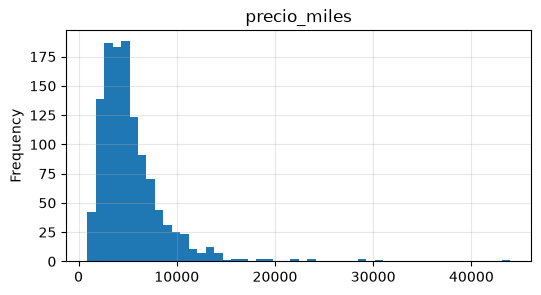

In [6]:
print(f"media = {viv.precio_miles.mean():,.0f}   mediana = {viv.precio_miles.median():,.0f}")
viv.precio_miles.plot.hist(bins=50, figsize=(6, 3), title="precio_miles");

**Respuesta:**

`precio_miles` presenta el mayor sesgo hacia valores altos (**3.38**): pocas viviendas muy caras alargan su cola derecha.   
La curtosis excedente **22.95** refleja gran influencia de observaciones extremas frente a una normal.  
Estos precios elevan la media (**5 271**) sobre la mediana (**4 503.5**), en miles de pesos.  
Usaría la **mediana** como precio típico porque su posición central la hace menos sensible a esos extremos.


### Pregunta I.3 · Regla del IQR  *(5 pts)*

Escribe la función `atipicos_iqr(s, k=1.5)` que, dada una Series `s`, devuelva una Series booleana que marque como atípicos los valores fuera de $[Q_1 - k\,\mathrm{IQR},\; Q_3 + k\,\mathrm{IQR}]$ (ignora los `NaN`). Después cuenta los atípicos de cada variable de `NUM`.

In [7]:
def atipicos_iqr(s, k=1.5):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)


n_atip = {c: int(atipicos_iqr(viv[c]).sum()) for c in NUM}
print(n_atip)


{'superficie_m2': 20, 'recamaras': 78, 'antiguedad_anios': 37, 'dist_centro_km': 25, 'precio_miles': 57}


### Pregunta I.4 · El logaritmo y los atípicos  *(4 pts)*

Crea `log_precio = np.log(viv.precio_miles)`, calcula su asimetría y cuántos atípicos marca la regla del IQR. Luego responde en **3 a 4 líneas**: ¿la transformación resolvió el problema de los atípicos? Entre eliminarlos, dejarlos o transformarlos, ¿qué harías con las viviendas más caras y por qué? (Recuerda cómo se generó el dato: hay viviendas con precios muy superiores al de su tipo.)

In [8]:
log_precio = np.log(viv.precio_miles)
asim_log = log_precio.skew()
n_atip_log = int(atipicos_iqr(log_precio).sum())
print(f"asimetría: {asim_log:.2f}   atípicos: {n_atip_log}")


asimetría: 0.22   atípicos: 14


**Respuesta:**

El logaritmo comprime la cola: la asimetría baja **3.38→0.22** y las marcas del IQR **57→14**.  
Mejora la forma de la distribución, pero no valida precios ni corrige sobreprecios frente a viviendas comparables.  
Verificaría fuente, zona, superficie y acabados; conservaría casos legítimos y modelaría **log(precio)** para reducir su influencia.  
Corregiría errores confirmados y excluiría solo los irrecuperables, pues borrar viviendas caras legítimas sesgaría la muestra.


### Pregunta I.5 · Pearson, Spearman y transformaciones  *(6 pts)*

Calcula, entre el precio y `superficie_m2`, cuatro coeficientes y guárdalos en el dict `r`:
`"pearson_crudo"` (precio sin transformar), `"pearson_log"` (con `log_precio`), `"spearman_crudo"` y `"spearman_log"`.
Después explica en **3 a 4 líneas**: (a) por qué `spearman_crudo` y `spearman_log` coinciden, y (b) por qué `pearson_crudo` y `pearson_log` no.

In [9]:
d = pd.DataFrame({"precio": viv.precio_miles, "log_precio": log_precio, "superficie": viv.superficie_m2})

r = {
    "pearson_crudo": d["precio"].corr(d["superficie"], method="pearson"),
    "pearson_log": d["log_precio"].corr(d["superficie"], method="pearson"),
    "spearman_crudo": d["precio"].corr(d["superficie"], method="spearman"),
    "spearman_log": d["log_precio"].corr(d["superficie"], method="spearman"),
}
print({k: round(v, 3) for k, v in r.items()})


{'pearson_crudo': np.float64(0.546), 'pearson_log': np.float64(0.616), 'spearman_crudo': np.float64(0.637), 'spearman_log': np.float64(0.637)}


**Respuesta:**

**Spearman (0.637 en ambos casos)** mide la asociación entre rangos, sin utilizar las distancias originales entre precios.  
El logaritmo es estrictamente creciente para precios positivos: conserva el orden y los empates, por lo que esos rangos no cambian.  
**Pearson (0.546→0.616)** usa magnitudes para medir asociación lineal y no es invariante ante transformaciones no lineales.  
Al comprimir los precios altos, el log modifica su influencia y aquí aumenta la asociación lineal con superficie; este aumento no está garantizado.


### Pregunta I.6 · Verdadero o falso  *(4 pts)*

Marca cada afirmación como `True` (verdadera) o `False` (falsa). Cada acierto vale 1 punto; no hay penalización por error.

- **a)** Si el coeficiente de correlación de Pearson entre $X$ e $Y$ es 0, entonces $X$ e $Y$ son independientes.
- **b)** La mediana es más robusta que la media frente a valores atípicos.
- **c)** Una correlación de 0.9 entre las ventas de helado y los ahogamientos demuestra que el helado causa ahogamientos.
- **d)** Una curtosis excedente positiva indica colas más pesadas que las de una distribución normal.

In [10]:
resp_VF = {"a": False, "b": True, "c": False, "d": True}
print(resp_VF)
# a: correlación lineal nula no implica independencia.
# c: una correlación no demuestra causalidad; puede existir un factor común.


{'a': False, 'b': True, 'c': False, 'd': True}


**Justificación de los incisos:**

- **a) Falso.** Pearson mide asociación lineal; puede ser cero con dependencia no lineal. Si $X\sim U(-1,1)$ e $Y=X^2$, la correlación es cero por simetría, aunque $Y$ depende de $X$.

- **b) Verdadero.** La mediana depende de los valores centrales ordenados; la media incorpora todas las magnitudes. Por eso, los valores extremos pueden desplazar mucho más la media.

- **c) Falso.** Una correlación alta no demuestra causalidad. El calor podría aumentar tanto las ventas de helados como la exposición al agua y los ahogamientos, actuando como factor de confusión.

- **d) Verdadero.** La curtosis excedente positiva significa que el cuarto momento estandarizado supera **3**, valor de la normal. Refleja mayor peso de valores extremos, sin implicar necesariamente un pico más alto.


### Pregunta I.7 · Matriz de correlación y multicolinealidad  *(4 pts)*

Calcula la matriz de correlación de Pearson de `superficie_m2`, `recamaras`, `antiguedad_anios`, `dist_centro_km` y `log_precio`, dibújala como mapa de calor (con barra de color y etiquetas) y guarda en `par` la tupla con los nombres de las **dos variables explicativas** (sin contar `log_precio`) más correlacionadas entre sí en valor absoluto. En **2 a 3 líneas**: ¿por qué sería un problema meter ambas en una regresión lineal y qué harías?

('superficie_m2', 'recamaras') r = 0.829

Correlación de cada predictor con log_precio:
superficie_m2       0.616
recamaras           0.525
antiguedad_anios   -0.116
dist_centro_km     -0.298
Candidata a eliminar del par si se mantiene regresión lineal: recamaras


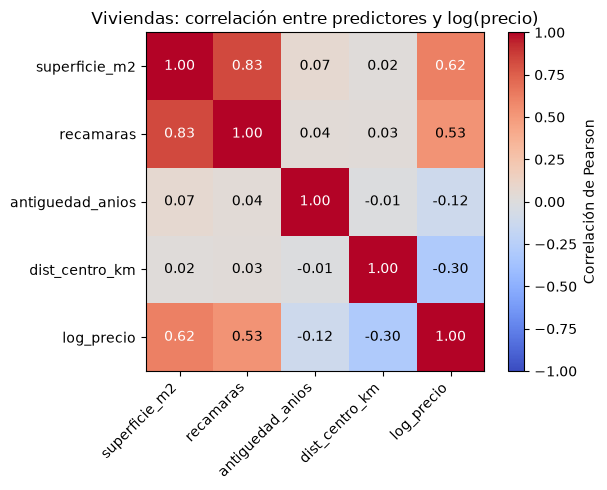

In [11]:
cols = ["superficie_m2", "recamaras", "antiguedad_anios", "dist_centro_km"]
C = viv[cols].assign(log_precio=log_precio).corr(method="pearson")

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(C, cmap="coolwarm", vmin=-1, vmax=1)
fig.colorbar(im, ax=ax, label="Correlación de Pearson", fraction=0.046, pad=0.04)
ax.set_xticks(np.arange(len(C.columns)), labels=C.columns, rotation=45, ha="right")
ax.set_yticks(np.arange(len(C.index)), labels=C.index)
for i in range(len(C)):
    for j in range(len(C)):
        ax.text(j, i, f"{C.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(C.iloc[i, j]) > 0.6 else "black")
ax.set_title("Viviendas: correlación entre predictores y log(precio)")
ax.grid(False)
fig.tight_layout()

# Triángulo superior: excluye la diagonal, los pares duplicados y el objetivo.
C_x = C.loc[cols, cols].abs()
triangulo = np.triu(np.ones(C_x.shape, dtype=bool), k=1)
par = C_x.where(triangulo).stack().idxmax()
print(par, f"r = {C.loc[par[0], par[1]]:.3f}")
# Relación de cada predictor con el objetivo utilizado en esta matriz.
corr_objetivo = C.loc[cols, "log_precio"].rename("r_con_log_precio")
print("\nCorrelación de cada predictor con log_precio:")
print(corr_objetivo.round(3).to_string())
# Comparar solo las dos variables del par multicolineal, en valor absoluto.
var_menor_corr = corr_objetivo.loc[list(par)].abs().idxmin()
print("Candidata a eliminar del par si se mantiene regresión lineal:", var_menor_corr)
plt.show()


**Respuesta:**

La correlación entre `superficie_m2` y `recamaras` (**r = 0.829**) dificulta separar sus efectos y puede volver inestables los coeficientes.  
Sin regularización, podría eliminar **`recamaras`**: su **|r|** con **`log_precio`** es **0.525**, frente a **0.616** de superficie.  
También podría conservar ambas con **Ridge**, cuya penalización **L2** estabiliza los coeficientes; escalaría los predictores y compararía ambas opciones mediante CV.


---
## Parte II — Preprocesamiento de datos (35 puntos)

Seguimos con el conjunto `viv`. Ahora el objetivo es **predecir `log(precio_miles)`** con un modelo lineal, cuidando el preprocesamiento.

### Pregunta II.1 · Cuantificar los valores faltantes  *(4 pts)*

Calcula (a) el número y el porcentaje de valores faltantes por columna y (b) la **proporción de faltantes por `zona`** para `antiguedad_anios` y `superficie_m2`.

In [12]:
faltantes = pd.DataFrame({"n": viv.isna().sum(), "%": 100 * viv.isna().mean()})
falt_por_zona = (
    viv[["antiguedad_anios", "superficie_m2"]]
    .isna()
    .groupby(viv["zona"])
    .mean()
)

print(faltantes[faltantes["n"] > 0].round(2))
print((100 * falt_por_zona).round(1))
print(f"Filas que se perderían al borrar incompletas: {viv.isna().any(axis=1).sum()}")


                    n     %
superficie_m2      62  5.17
antiguedad_anios  107  8.92
          antiguedad_anios  superficie_m2
zona                                     
Centro                 2.2            6.7
Costa                  0.0            4.0
Norte                  3.0            4.0
Oriente               19.1            4.4
Poniente               4.4            5.2
Sur                   21.6            6.6
Filas que se perderían al borrar incompletas: 163


### Pregunta II.2 · Mecanismo de los faltantes  *(3 pts)*

Con lo que observaste en II.1, ¿qué mecanismo (MCAR, MAR o MNAR) es más plausible para `antiguedad_anios` y cuál para `superficie_m2`? Justifica con los números. ¿Qué riesgo habría al **borrar** las filas incompletas?

**Respuesta:**

**Antigüedad: MAR** es más plausible: falta **21.6 % en Sur** y **19.1 % en Oriente**, frente a **0–4.4 %** en otras zonas. La ausencia se relaciona con `zona`; mientras que, bajo **MCAR**, esperaríamos tasas similares.  
**Superficie: MCAR** es más plausible: las tasas **3.9–6.7 %** son relativamente parecidas, compatibles con omisiones al azar, sin dependencia clara de la zona.  
Las tablas no prueban estos mecanismos ni descartan **MNAR**, donde faltar depende de la propia antigüedad o superficie no registrada.  
Borrar incompletos perdería **163 viviendas (13.6 %)** y subrepresentaría Sur/Oriente, reduciendo precisión y pudiendo sesgar las conclusiones.


### Pregunta II.3 · División entrenamiento / prueba  *(5 pts)*

Define `X = viv` sin `precio_miles` e `y = log_precio`. Separa 80 % para entrenamiento y 20 % para prueba (`random_state=0`) **estratificando por `zona`**, y muestra la proporción de cada zona en `X_train` y `X_test`. En **2 líneas**: ¿por qué conviene estratificar en este conjunto?

In [13]:
X = viv.drop(columns="precio_miles")
y = log_precio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=0, stratify=X["zona"]
)

prop = pd.DataFrame({
    "train": X_train["zona"].value_counts(normalize=True),
    "test": X_test["zona"].value_counts(normalize=True),
}).sort_index()
print((100 * prop).round(1))
print(f"Entrenamiento: {len(X_train)}; prueba: {len(X_test)}")


          train  test
zona                 
Centro     15.0  15.0
Costa       2.1   2.1
Norte      27.4  27.5
Oriente    15.3  15.0
Poniente   22.5  22.5
Sur        17.7  17.9
Entrenamiento: 960; prueba: 240


**Respuesta:**

La zona influye en el precio; estratificar conserva proporciones similares en entrenamiento y prueba, reduciendo la variabilidad de la evaluación debida a su composición.  
Así, **Costa (2.1 %)** aporta **20 viviendas al entrenamiento y 5 a prueba**; se reduce el riesgo de que quede escasamente representada por azar.


### Pregunta II.4 · Detectar fuga de datos  *(4 pts)*

Un compañero escribe este código para “preparar los datos” y luego evalúa con validación cruzada:

```python
X_num = viv[["superficie_m2", "antiguedad_anios", "dist_centro_km"]]
X_num = SimpleImputer(strategy="mean").fit_transform(X_num)      # (1)
X_num = StandardScaler().fit_transform(X_num)                    # (2)
scores = cross_val_score(Ridge(), X_num, log_precio, cv=5)       # (3)
```

Explica **qué información se filtra** en los pasos (1) y (2), por qué es un problema y cómo lo corregirías (en palabras, sin escribir todo el código).

**Respuesta:**

En (1), las medias de imputación incluyen filas que después serán de validación.  
En (2), también se filtran las medias y desviaciones estándar del escalado.  
Así, la validación influye en preparar el modelo y puede producir una evaluación optimista.  
Usaría **imputación → escalado → Ridge** en un `Pipeline`, reajustando todos los pasos solo con el entrenamiento de cada partición.


### Pregunta II.5 · Pipeline de preprocesamiento + modelo  *(10 pts)*

Construye un `Pipeline` que, **sin fuga de datos**, haga:

1. Variables numéricas (`superficie_m2`, `recamaras`, `antiguedad_anios`, `dist_centro_km`): imputación y un escalador de tu elección.
2. Variable nominal `zona`: imputación (por si acaso) y codificación *one-hot* **tolerante a categorías no vistas**.
3. Variable ordinal `acabados`: codificación ordinal respetando Básico < Medio < Alto < Premium.
4. Modelo: `Ridge(alpha=1.0)`.

Evalúa con validación cruzada de 5 particiones **solo con el entrenamiento** (reporta el RMSE medio sobre `log(precio)`), ajusta con todo el entrenamiento y reporta el RMSE en prueba. Justifica en 2 líneas tu elección de imputador y escalador.

In [14]:
from sklearn.base import clone
from sklearn.impute import KNNImputer

NUM_X = ["superficie_m2", "recamaras", "antiguedad_anios", "dist_centro_km"]
NOM = ["zona"]
ORD = ["acabados"]

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler()),
])
nom_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
ord_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ordinal", OrdinalEncoder(categories=[["Básico", "Medio", "Alto", "Premium"]])),
])

pre = ColumnTransformer([
    ("num", num_pipe, NUM_X),
    ("nom", nom_pipe, NOM),
    ("ord", ord_pipe, ORD),
])
modelo = Pipeline([("pre", pre), ("ridge", Ridge(alpha=1.0))])

cv = KFold(5, shuffle=True, random_state=0)
rmse_particiones = -cross_val_score(
    modelo, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error",
    error_score="raise",
)
rmse_cv = rmse_particiones.mean()

# Alternativa
# RobustScaler conserva los NaN: primero iguala escalas y después KNN imputa.
num_pipe_knn = Pipeline([
    ("scaler", RobustScaler()),
    ("imputer", KNNImputer(n_neighbors=5)),
])
modelo_knn = clone(modelo).set_params(pre__num=num_pipe_knn)
rmse_particiones_knn = -cross_val_score(
    modelo_knn, X_train, y_train, cv=cv,
    scoring="neg_root_mean_squared_error", error_score="raise",
)
rmse_cv_knn = rmse_particiones_knn.mean()
comparacion_cv = pd.DataFrame({
    "Mediana": rmse_particiones,
    "KNN (k=5)": rmse_particiones_knn,
}, index=pd.Index(range(1, 6), name="Partición"))
print("Comparación solo en entrenamiento; RMSE de log(precio):")
print(comparacion_cv.round(6).to_string())
print("RMSE CV medio:")
print(comparacion_cv.mean().round(6).to_string())

# La pequeña mejora media de KNN no se mantiene en todas las particiones.
# Se conserva la mediana por su simplicidad; test no participa en esta decisión.
modelo.fit(X_train, y_train)
rmse_test = np.sqrt(mean_squared_error(y_test, modelo.predict(X_test)))

print(f"RMSE CV = {rmse_cv:.3f}    RMSE prueba = {rmse_test:.3f}")
print("RMSE por partición:", np.round(rmse_particiones, 3))


Comparación solo en entrenamiento; RMSE de log(precio):
            Mediana  KNN (k=5)
Partición                     
1          0.223022   0.223797
2          0.262675   0.262352
3          0.290243   0.295909
4          0.246050   0.242894
5          0.250506   0.243137
RMSE CV medio:
Mediana      0.254499
KNN (k=5)    0.253618
RMSE CV = 0.254    RMSE prueba = 0.251
RMSE por partición: [0.223 0.263 0.29  0.246 0.251]


**Respuesta:**

Elijo **mediana** por asimetría y atípicos, y **moda** para categorías; la media es sensible a extremos y aquí no se justifica una constante. Pruebo **KNN** para aprovechar relaciones entre variables.  
Conservo mediana por simplicidad ante la mínima mejora de KNN (**RMSE CV: 0.2545→0.2536**); **RobustScaler** resiste extremos y hace comparables las escalas para Ridge; precede a KNN porque usa distancias.


### Pregunta II.6 · Escalador y atípicos  *(4 pts)*

Toma `superficie_m2` del conjunto de entrenamiento (imputando antes los `NaN` con la mediana) y **añade un registro mal capturado de 5 000 m²**. Aplica `StandardScaler` y `RobustScaler`. Para cada resultado calcula el **rango intercuartílico** de la variable escalada y su **valor absoluto máximo**. En **2 a 3 líneas**: ¿qué escalador es más sensible a los atípicos y por qué? ¿Para qué tipo de modelos importa escalar?

In [15]:
s = X_train["superficie_m2"].fillna(X_train["superficie_m2"].median())
s = pd.concat([s, pd.Series([5000.0])], ignore_index=True).to_frame()

z_std = StandardScaler().fit_transform(s).ravel()
z_rob = RobustScaler().fit_transform(s).ravel()

def resumen(z):
    q1, q3 = np.percentile(z, [25, 75])
    return {"IQR": round(q3 - q1, 3), "|max|": round(np.abs(z).max(), 2)}

print("Standard:", resumen(z_std))
print("Robust:  ", resumen(z_rob))


Standard: {'IQR': np.float64(0.354), '|max|': np.float64(29.78)}
Robust:   {'IQR': np.float64(1.0), '|max|': np.float64(84.28)}


**Respuesta:**

**StandardScaler** es más sensible: el extremo desplaza la media e infla la desviación estándar, que usa diferencias al cuadrado; el **IQR cae a 0.354**.  
**RobustScaler** usa mediana y cuartiles, definidos por posiciones y poco alterados por un extremo aislado; conserva **IQR = 1**, sin eliminar el dato (**máximo absoluto = 84.28**).  
Escalar importa por distancias o márgenes (**KNN/SVM**) y por penalización (**Ridge/logística**); los árboles generalmente no lo requieren.


### Pregunta II.7 · Categorías no vistas y codificación  *(5 pts)*

Ajusta un `OneHotEncoder` **con el valor por defecto** y otro con `handle_unknown="ignore"` usando solo las filas de `X_train` cuya `zona` **no** sea `Costa`. Luego transforma una vivienda de `Costa` con cada uno: captura el error del primero (`msg_error`) y guarda la fila resultante del segundo (`fila_ignore`).
En **2 líneas**: ¿qué problema aparece si en lugar de *one-hot* codificas `zona` con enteros (0, 1, 2, …) en un modelo lineal?

In [16]:
sin_costa = X_train.loc[X_train["zona"] != "Costa", ["zona"]]
nueva = pd.DataFrame({"zona": ["Costa"]})

msg_error = None
try:
    OneHotEncoder().fit(sin_costa).transform(nueva)
except ValueError as e:
    msg_error = str(e)[:90]

enc_ignore = OneHotEncoder(handle_unknown="ignore").fit(sin_costa)
fila_ignore = enc_ignore.transform(nueva).toarray()

print("Error:", msg_error)
print("Fila con ignore:", fila_ignore)


Error: Found unknown categories ['Costa'] in column 0 during transform
Fila con ignore: [[0. 0. 0. 0. 0.]]


**Respuesta:**

Los enteros impondrían a `zona` un orden y distancias arbitrarios, inexistentes en una variable nominal.  
El modelo forzaría un efecto proporcional a esos códigos; **one-hot** permite estimar un efecto distinto por categoría.


---
## Parte III — Ingeniería y selección de variables (35 puntos)

Ahora `X_b` contiene **26 mediciones de laboratorio** de 400 pacientes y `y_b` es un diagnóstico binario (0/1). Algunas variables
son útiles y otras no. Toda evaluación de desempeño debe hacerse con **validación cruzada** (`cv_b`) y, cuando haya selección o
escalado, **dentro de un `Pipeline`**.

In [17]:
X_b, y_b = genera_biomarcadores()
cv_b = StratifiedKFold(5, shuffle=True, random_state=0)
print(X_b.shape, y_b.value_counts().to_dict())

(400, 26) {1: 213, 0: 187}


### Pregunta III.1 · Umbral de varianza  *(5 pts)*

Aplica `VarianceThreshold(threshold=0.01)` a `X_b` en su escala original y guarda en `quitadas_crudo` la lista de variables eliminadas. Repite con `X_b` estandarizada y guarda en `n_quitadas_std` cuántas elimina. En **3 líneas**: ¿qué enseñan los dos resultados sobre el umbral de varianza como criterio de selección?

In [18]:
var_crudo = VarianceThreshold(threshold=0.01).fit(X_b)
quitadas_crudo = X_b.columns[~var_crudo.get_support()].tolist()
var_std = make_pipeline(StandardScaler(), VarianceThreshold(threshold=0.01))
var_std.fit(X_b)
n_quitadas_std = int((~var_std.named_steps["variancethreshold"].get_support()).sum())

print("Original:", quitadas_crudo)
print("Estandarizada:", n_quitadas_std)


Original: ['lin_c', 'casi_const']
Estandarizada: 0


**Respuesta:**

En crudo se eliminan **`lin_c` y `casi_const`**; la primera es informativa, pero su escala pequeña deja la varianza por debajo de **0.01**.  
Al estandarizar, todas las variables no constantes pasan a varianza **1**, incluso `casi_const`: el mismo umbral no elimina ninguna.  
El filtro no utiliza **`y`** y depende de las unidades ($\operatorname{Var}(aX)=a^2\operatorname{Var}(X)$); por eso, baja varianza no demuestra irrelevancia predictiva.


### Pregunta III.2 · Filtros: F de ANOVA vs. información mutua  *(6 pts)*

Selecciona las 5 mejores variables con `SelectKBest` usando (a) `f_classif` y (b) `mutual_info_classif` (con `random_state=0`). Guarda los nombres en `sel_F` y `sel_MI`. En **3 a 4 líneas**: ¿qué variable distingue ambos resultados y por qué un filtro la ve y el otro no? (Pista: calcula la correlación de Pearson de esa variable con `y_b`.)

In [19]:
from functools import partial

filtro_F = SelectKBest(score_func=f_classif, k=5).fit(X_b, y_b)
filtro_MI = SelectKBest(
    score_func=partial(mutual_info_classif, random_state=0), k=5
).fit(X_b, y_b)
sel_F = X_b.columns[filtro_F.get_support()].tolist()
sel_MI = X_b.columns[filtro_MI.get_support()].tolist()

print("F :", sel_F)
print("MI:", sel_MI)
print(f"Pearson(cuad, y) = {X_b['cuad'].corr(y_b):.3f}")


F : ['lin_a', 'lin_b', 'lin_c', 'lin_a_copia', 'ruido_08']
MI: ['lin_a', 'lin_b', 'lin_c', 'cuad', 'lin_a_copia']
Pearson(cuad, y) = -0.024


**Respuesta:**

MI conserva **`cuad`**, mientras F selecciona `ruido_08` en su lugar.  
En `cuad`, las clases tienen medias similares, pero la clase 1 presenta magnitudes mayores; Pearson es **−0.024**.  
ANOVA F contrasta medias y por eso puntúa débilmente esta relación.  
MI detecta que la distribución cambia con el diagnóstico, aunque la dependencia no sea lineal.


### Pregunta III.3 · Redundancia  *(4 pts)*

Calcula la matriz de correlación de las variables de `sel_MI` y guarda en `par_redundante` el par con mayor correlación absoluta. En **2 líneas**: ¿por qué un filtro univariado no evita este problema y qué harías al respecto?

In [20]:
R = X_b[sel_MI].corr(method="pearson")
triangulo_MI = np.triu(np.ones(R.shape, dtype=bool), k=1)
par_redundante = R.abs().where(triangulo_MI).stack().idxmax()
print(par_redundante, round(abs(R.loc[par_redundante[0], par_redundante[1]]), 3))


('lin_a', 'lin_a_copia') 0.994


**Respuesta:**

El filtro evalúa cada variable frente a **`y`** por separado, sin descontar señal compartida; por eso conserva **`lin_a` y `lin_a_copia` (r = 0.994)**.  
Eliminaría **`lin_a_copia`**: añade ruido independiente a `lin_a`, sin aportar señal adicional sobre `y`; la CV evaluaría el modelo reducido, pero no es necesaria para justificar esta redundancia conocida.


### Pregunta III.4 · Envoltura: RFE y RFECV  *(6 pts)*

Con regresión logística (`max_iter=1000`) y **estandarizando dentro del pipeline**:
(a) usa `RFE` para conservar 6 variables y guarda sus nombres en `sel_rfe`;
(b) usa `RFECV` (con `cv_b` y `scoring="accuracy"`) y guarda en `k_opt` el número de variables que recomienda.
En **3 líneas**: ¿`RFE` con regresión logística recupera `cuad`? ¿Por qué? ¿Qué costo tiene frente a un filtro?

In [21]:
from sklearn.base import clone

# III.3: lin_a_copia añade ruido independiente a lin_a (r = 0.994).
# Su exclusión es fija, por construcción conocida, y no se aprende con validación.
redundantes_rfe = ["lin_a_copia"]
cols_sin_redundancia = X_b.columns.drop(redundantes_rfe).tolist()
pre_sin_redundancia = ColumnTransformer([
    ("conservar", "passthrough", cols_sin_redundancia),
], remainder="drop", verbose_feature_names_out=False)

pipe_rfe = Pipeline([
    ("sin_redundancia", clone(pre_sin_redundancia)),
    ("scaler", StandardScaler()),
    ("rfe", RFE(LogisticRegression(max_iter=1000), n_features_to_select=6)),
])
pipe_rfe.fit(X_b, y_b)
nombres_rfe = pipe_rfe.named_steps["sin_redundancia"].get_feature_names_out()
sel_rfe = nombres_rfe[pipe_rfe.named_steps["rfe"].get_support()].tolist()

# El escalador de RFECV se reajusta en cada partición interna.
# La exclusión anterior solo retira una columna definida de antemano.
estimador_rfecv = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(max_iter=1000)),
])
pipe_cv = Pipeline([
    ("sin_redundancia", clone(pre_sin_redundancia)),
    ("rfecv", RFECV(
        estimator=estimador_rfecv, cv=cv_b, scoring="accuracy",
        importance_getter="named_steps.lr.coef_",
    )),
])
pipe_cv.fit(X_b, y_b)
k_opt = int(pipe_cv.named_steps["rfecv"].n_features_)
nombres_rfecv = pipe_cv.named_steps["sin_redundancia"].get_feature_names_out()
sel_rfecv = nombres_rfecv[pipe_cv.named_steps["rfecv"].get_support()].tolist()

print("Variable excluida por redundancia:", redundantes_rfe)
print("Predictores disponibles tras preprocesar:", len(nombres_rfe))
print("RFE (6 variables):", sel_rfe)
print("k óptimo:", k_opt)
print("RFECV:", sel_rfecv)


Variable excluida por redundancia: ['lin_a_copia']
Predictores disponibles tras preprocesar: 25
RFE (6 variables): ['lin_a', 'lin_b', 'lin_c', 'ruido_05', 'ruido_06', 'ruido_19']
k óptimo: 3
RFECV: ['lin_a', 'lin_b', 'lin_c']


**Respuesta:**

Excluyo **`lin_a_copia`** antes de ambos selectores por su redundancia conocida con `lin_a` (**r = 0.994**); quedan **25 predictores**.  
RFE no conserva **`cuad`**: una logística lineal no representa su señal basada en magnitudes grandes de ambos signos sin una transformación como **`cuad²`**.  
RFE requiere ajustar repetidamente el modelo y cuesta más que un filtro; RFECV repite la eliminación por particiones y recomienda **3 variables**.


### Pregunta III.5 · Selección integrada: regresión logística L1  *(4 pts)*

Para $C \in \{0.005,\,0.01,\,0.05,\,0.1,\,1\}$, ajusta `LogisticRegression(penalty="l1", solver="liblinear", C=C)` sobre `X_b` estandarizada, usando `SelectFromModel`, y guarda en `n_sel` un dict `{C: número de variables seleccionadas}`. En **2 líneas**: ¿cómo se relaciona $C$ con el número de variables y qué ventaja tiene este método frente a un filtro?

In [22]:
n_sel = {}
for C in [0.005, 0.01, 0.05, 0.1, 1]:
    pipe_l1 = Pipeline([
        ("scaler", StandardScaler()),
        ("sel", SelectFromModel(LogisticRegression(
            penalty="l1", solver="liblinear", C=C,
            max_iter=1000, random_state=0,
        ))),
    ])
    pipe_l1.fit(X_b, y_b)
    n_sel[C] = int(pipe_l1.named_steps["sel"].get_support().sum())
print(n_sel)


{0.005: 0, 0.01: 2, 0.05: 4, 0.1: 4, 1: 23}


**Respuesta:**

**L1** penaliza la suma de valores absolutos de los coeficientes y puede anularlos; al aumentar **C**, disminuye la regularización y aquí se conservan **0, 2, 4, 4 y 23** variables.  
Frente al filtro univariado, que puntúa variables aisladamente, selecciona durante el ajuste conjunto y considera sus aportes al modelo; elegiría **C** mediante CV para equilibrar ajuste y complejidad.


### Pregunta III.6 · Fuga de datos en la selección de variables  *(6 pts)*

Generamos datos de **puro ruido**: `Xn` con 100 filas y 1 000 columnas aleatorias, y `yn` aleatoria; por construcción, ningún modelo puede predecir `yn` mejor que el azar (exactitud ≈ 0.5).

(a) **Mal:** selecciona las 20 mejores columnas con `SelectKBest(f_classif)` usando *todos* los datos y luego evalúa una regresión logística con validación cruzada → `acc_mal`.
(b) **Bien:** pon la selección y el modelo en un `Pipeline` y evalúa con la misma validación cruzada → `acc_bien`.
En **3 líneas**: explica la diferencia y qué regla de la receta de selección se viola en (a).

In [23]:
rng = np.random.default_rng(0)
Xn = rng.normal(size=(100, 1000))
yn = rng.integers(0, 2, 100)

Xn_mal = SelectKBest(f_classif, k=20).fit_transform(Xn, yn)
acc_mal = cross_val_score(
    LogisticRegression(max_iter=1000), Xn_mal, yn,
    cv=cv_b, scoring="accuracy", error_score="raise",
).mean()

pipe_bien = Pipeline([
    ("sel", SelectKBest(f_classif, k=20)),
    ("lr", LogisticRegression(max_iter=1000)),
])
acc_bien = cross_val_score(
    pipe_bien, Xn, yn, cv=cv_b, scoring="accuracy", error_score="raise",
).mean()
print(f"Mal: {acc_mal:.2f}    Bien: {acc_bien:.2f}")


Mal: 0.85    Bien: 0.57


**Respuesta:**

El **0.85** es artificial: el selector usó etiquetas de validación para elegir entre mil correlaciones accidentales.  
Dentro del pipeline desconoce esas etiquetas y obtiene **0.57**, una fluctuación posible alrededor del azar.  
Se viola la regla de aprender la selección solo con entrenamiento; debe repetirse dentro de cada partición.


### Pregunta III.7 · Ingeniería de variables y polinomios  *(4 pts)*

(a) Agrega a `X_b` la variable `cuad_2 = cuad**2`, y compara la exactitud media (CV con `cv_b`) de una regresión logística estandarizada **sin** y **con** la nueva variable (`acc_base`, `acc_nueva`).
(b) Sin ejecutar código, ¿cuántas columnas produce `PolynomialFeatures(degree=3, include_bias=False)` sobre 10 variables? Guarda tu cálculo (fórmula) en `n_poly` y **verifícalo** con scikit-learn. En **1 línea**: ¿qué riesgo implica esta “explosión” de columnas?

In [24]:
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

acc_base = cross_val_score(
    lr, X_b, y_b, cv=cv_b, scoring="accuracy", error_score="raise",
).mean()
# Transformación por fila y sin parámetros aprendidos: no usa etiquetas ni modifica X_b.
X_b_nueva = X_b.assign(cuad_2=X_b["cuad"] ** 2)
acc_nueva = cross_val_score(
    lr, X_b_nueva, y_b, cv=cv_b, scoring="accuracy", error_score="raise",
).mean()
print(f"Base: {acc_base:.3f}    Con cuad_2: {acc_nueva:.3f}")

from math import comb
# Combinaciones con repetición de grados 0 a 3, menos la columna constante.
n_poly = comb(10 + 3, 3) - 1
n_poly_sk = PolynomialFeatures(degree=3, include_bias=False).fit(
    np.zeros((1, 10))
).n_output_features_
print(n_poly, n_poly_sk)


Base: 0.903    Con cuad_2: 0.968
285 285


**Respuesta:**

Las **285 columnas** facilitan ajustar ruido: aumentan el riesgo de sobreajuste, la colinealidad y el costo computacional.


---
**Fin del examen.** Reinicia el kernel, ejecuta todo el notebook y verifica que corra sin errores antes de entregar.